# Import library dan load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv("data/CC_Customer_Dataset.csv")
df.shape

(660, 7)

In [2]:
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.describe()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


In [4]:
print('missing value:\n', df.isna().sum())
print('duplikat:', df.duplicated().sum())

missing value:
 Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64
duplikat: 0


# Soal 1, Scatterplot Avg_Credit_Limit vs Total_Credit_Cards

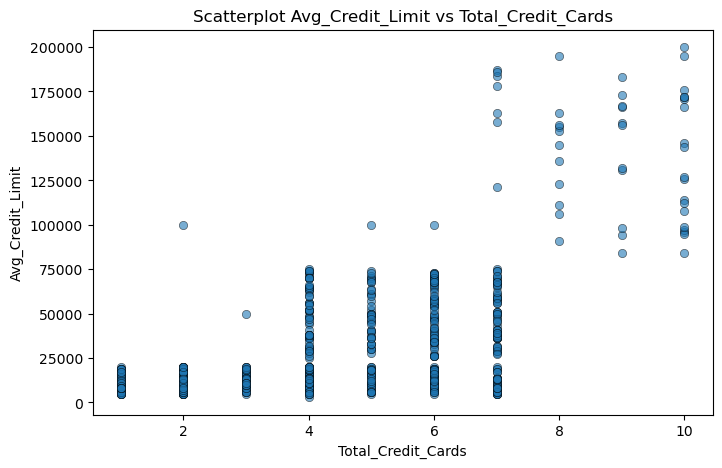

Koefisien korelasi Pearson: 0.609


In [5]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Total_Credit_Cards", y="Avg_Credit_Limit",
                alpha=0.6, edgecolor="k")
plt.title("Scatterplot Avg_Credit_Limit vs Total_Credit_Cards")
plt.xlabel("Total_Credit_Cards")
plt.ylabel("Avg_Credit_Limit")
plt.show()

r = df["Avg_Credit_Limit"].corr(df["Total_Credit_Cards"])
print(f"Koefisien korelasi Pearson: {r:.3f}")

# Soal 2, Elbow Method untuk K-Means

d:\Download\anaconda\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\Download\anaconda\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\Download\anaconda\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\Download\anaconda\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~

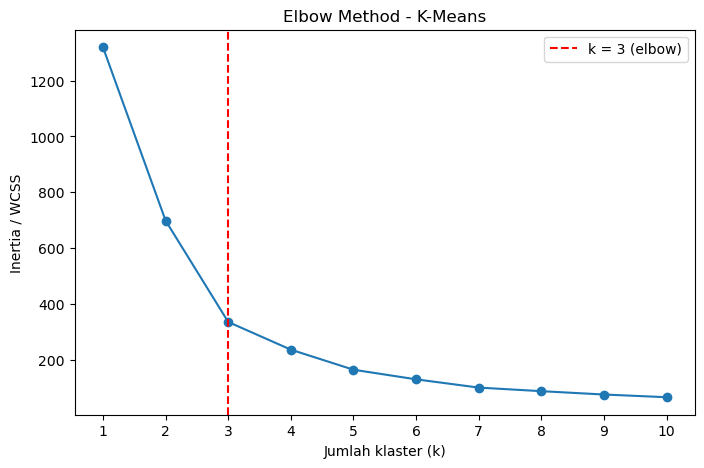

,k,WCSS
0,1,1320.0
1,2,698.3
2,3,334.7
3,4,235.4
4,5,163.5
5,6,129.0
6,7,99.4
7,8,86.5
8,9,74.5
9,10,64.8


In [6]:
X2 = StandardScaler().fit_transform(df[["Avg_Credit_Limit", "Total_Credit_Cards"]])

k_range = range(1, 11)
wcss = []
sil_scores = {}

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X2)
    wcss.append(km.inertia_)
    if k > 1:
        sil_scores[k] = silhouette_score(X2, km.labels_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), wcss, marker="o")
plt.axvline(3, color="red", linestyle="--", label="k = 3 (elbow)")
plt.title("Elbow Method - K-Means")
plt.xlabel("Jumlah klaster (k)")
plt.ylabel("Inertia / WCSS")
plt.xticks(list(k_range))
plt.legend()
plt.show()

pd.DataFrame({"k": list(k_range), "WCSS": np.round(wcss, 1)})

# Soal 3, Model K-Means dan visualisasinya

d:\Download\anaconda\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


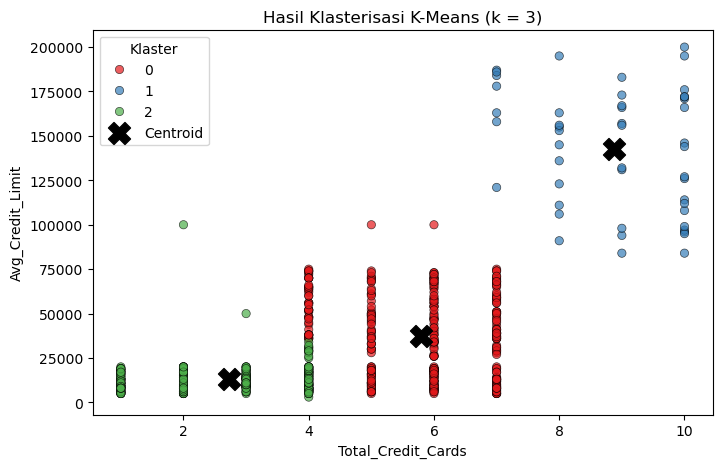

Silhouette Score K-Means: 0.49
               Avg_Credit_Limit       Total_Credit_Cards      
                           mean count               mean count
Cluster_KMeans                                                
0                       37160.6   330                5.8   330
1                      142750.0    48                8.9    48
2                       13134.8   282                2.7   282


In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Cluster_KMeans"] = kmeans.fit_predict(X2)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Total_Credit_Cards", y="Avg_Credit_Limit", hue="Cluster_KMeans", palette="Set1", alpha=0.7, edgecolor="k")

scaler2 = StandardScaler().fit(df[["Avg_Credit_Limit", "Total_Credit_Cards"]])
centroids = scaler2.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 1], centroids[:, 0], c="black", marker="X", s=250, label="Centroid")

plt.title("Hasil Klasterisasi K-Means (k = 3)")
plt.legend(title="Klaster")
plt.show()

print("Silhouette Score K-Means:", round(silhouette_score(X2, df["Cluster_KMeans"]), 3))
print(df.groupby("Cluster_KMeans")[["Avg_Credit_Limit", "Total_Credit_Cards"]].agg(["mean", "count"]).round(1))

# Soal 4, Persiapan data DBSCAN

In [8]:
features = ["Avg_Credit_Limit", "Total_Credit_Cards", "Total_visits_bank", "Total_visits_online", "Total_calls_made"]

X = StandardScaler().fit_transform(df[features])
print("Bentuk data:", X.shape)

Bentuk data: (660, 5)


# Soal 5, Elbow Method pada DBSCAN

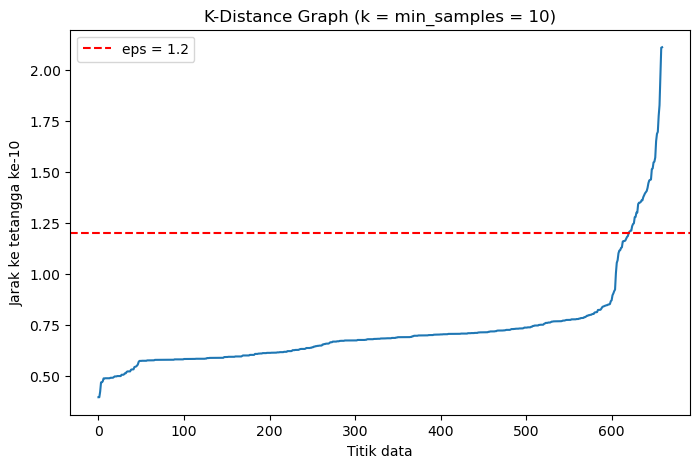

,eps,n_klaster,n_noise,silhouette
0,0.8,1,54,NaN
1,1.0,1,53,NaN
2,1.2,2,13,0.569
3,1.5,2,3,0.575
4,2.0,1,0,NaN


In [9]:
min_samples = 2 * X.shape[1]

nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, -1])

eps_pilihan = 1.2

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.axhline(eps_pilihan, color="red", linestyle="--", label=f"eps = {eps_pilihan}")
plt.title(f"K-Distance Graph (k = min_samples = {min_samples})")
plt.xlabel("Titik data")
plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.legend()
plt.show()

hasil = []
for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    lbl = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    mask = lbl != -1
    n_cl = len(set(lbl[mask]))
    sil = silhouette_score(X[mask], lbl[mask]) if n_cl > 1 else np.nan
    hasil.append({"eps": eps, "n_klaster": n_cl, "n_noise": int((~mask).sum()), "silhouette": round(sil, 3)})
pd.DataFrame(hasil)

Jumlah klaster : 2
Jumlah noise   : 13
Cluster_DBSCAN
-1     13
 0    608
 1     39
Name: count, dtype: int64


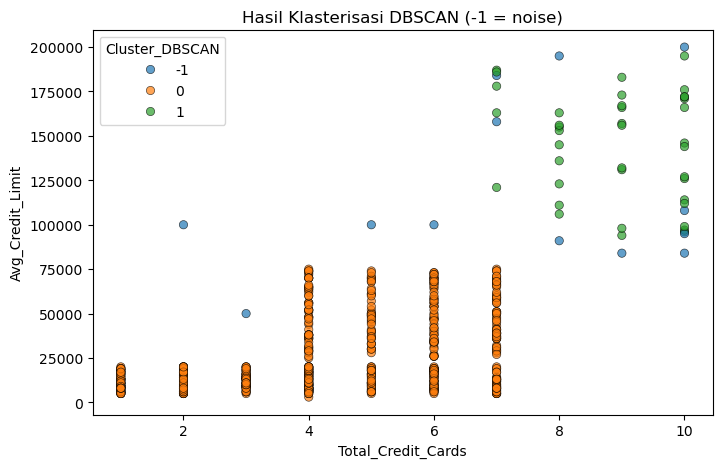

In [10]:
dbscan = DBSCAN(eps=1.2, min_samples=10)
df["Cluster_DBSCAN"] = dbscan.fit_predict(X)

n_klaster = len(set(df["Cluster_DBSCAN"])) - (1 if -1 in df["Cluster_DBSCAN"].values else 0)
n_noise = (df["Cluster_DBSCAN"] == -1).sum()
print(f"Jumlah klaster : {n_klaster}")
print(f"Jumlah noise   : {n_noise}")
print(df["Cluster_DBSCAN"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Total_Credit_Cards", y="Avg_Credit_Limit", hue="Cluster_DBSCAN", palette="tab10", alpha=0.7, edgecolor="k")
plt.title("Hasil Klasterisasi DBSCAN (-1 = noise)")
plt.show()

# Soal 6, Silhouette Score dan Davies-Bouldin Index

In [11]:
labels = df["Cluster_DBSCAN"].values
mask = labels != -1

sil = silhouette_score(X[mask], labels[mask])
dbi = davies_bouldin_score(X[mask], labels[mask])

print(f"Silhouette Score    : {sil:.3f}")
print(f"Davies-Bouldin Index: {dbi:.3f}")

Silhouette Score    : 0.569
Davies-Bouldin Index: 0.607
